# Thermal paleointensity: recover a past field from real magnetic measurements

## Problem

**Observation:** measured magnetic amplitudes and directions after 181 thermal laboratory treatments on five natural specimens. **Unknown:** their original cooling-field strengths, in microtesla. We retain all native check rows and reconstruct all five independently fixed intervals. This is an inverse parameter-estimation problem, not image classification or forward-only simulation.

**GT:** independent physical ground truth is unavailable for this binding. The evaluator uses a separately reproduced original standard-method result. Historical expected fields below are context, not truth; numerical parity cannot establish physical accuracy.

In [1]:
from pathlib import Path
import sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations,NAMES
from src.main import run
from src.visualization import comparison_figures
raw=load_observations(ROOT/'data/raw_data.npz')
with np.load(ROOT/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as z:
    upstream={k:z[k].copy() for k in z.files}
print('Specimens:',NAMES)
print('All real measured row counts:',raw['count'].tolist())
print('Known laboratory fields (µT):',raw['laboratory_field'].tolist())

Specimens: ('A-3-3', 'BR06-4F', 'HEL2-2d', 'KF-3-1', 'LV6C3A')
All real measured row counts: [[31, 37, 37, 30, 46]]
Known laboratory fields (µT): [[30.0, 50.25, 50.25, 60.0, 30.0]]


## Data

A-3-3 is 1960 Hawaiian lava; BR06-4F and HEL2-2d are 1906 Helsinki bricks; KF-3-1 is 1984 Krafla lava; LV6C3A is a 1993 Láscar andesitic clast. The official calibration compilation identifies instrument-measured thermal experiments. Amplitudes are author-processed import values normalized by their first measured amplitude, preserving measured directions and every check step. No synthetic observations replace these data.

The original compilation includes 20 specimens with mixed methods and intentionally poor cases. This benchmark fixes the five natural thermal cases that need no anisotropy/nonlinear correction, have original SCAT=true and original FRAC≥0.5. It does **not** describe all 20 as valid. Unselected and corrected cases remain provenance diagnostics. Padding is excluded solely by the explicit reading counts, never by fit quality.

## Physics

For measured amplitude m, declination d and inclination i, the north/east/down vector is $\mathbf m=m(\cos d\cos i,\sin d\cos i,\sin i)$. The acquired partial remanence is the **vector difference** between in-field and zero-field measurements. With measured initial magnitude M0,

$$x_j=\|\mathbf m^{\mathrm{in}}_j-\mathbf m^{\mathrm{zero}}_j\|/M_0,\qquad y_j=\|\mathbf m^{\mathrm{zero}}_j\|/M_0,$$
$$y_j=a-(B/B_{\mathrm{lab}})x_j+\epsilon_j.$$

Here j indexes temperature, a is an unknown intercept, B is the unknown cooling field, Blab is the known laboratory field, and epsilon covers noise and physical model discrepancy. Scalar magnitude subtraction loses directional information. Repeated heating checks test whether the material still behaves as the same recorder.

## Method

We actively use the locally extracted SPD signed standard-major-axis method. Let dx and dy be centered paired observations, n the number of fitted pairs, and Sxx, Syy, Sxy their sums of squares and cross-products:

$$b=\mathrm{sign}(S_{xy})\sqrt{S_{yy}/S_{xx}},\quad a=\bar y-b\bar x,\quad B=|b|B_{\mathrm{lab}},$$
$$\sigma_b=\sqrt{\frac{2S_{yy}-2bS_{xy}}{(n-2)S_{xx}}},\qquad\sigma_B=B_{\mathrm{lab}}\sigma_b.$$

The negative physical slope converts lost original remanence to acquired laboratory remanence. This closed-form inverse needs no optimizer or artificial iterations. The fixed author intervals are used unchanged.

Anchored and free PCA diagonalize the second-moment matrix of measured zero-field vectors, with or without centering. MAD is the angular spread derived from its three eigenvalues. FRAC divides the selected interval's vector-difference sum by the full series' vector-difference sum. SCAT tests the Arai points and eligible repeat/tail checks against a β=0.1 box around the fitted line. These diagnostics are freshly recomputed; they are not proof of geological accuracy.

In [2]:
started=time.perf_counter()
reconstruction,diagnostics=run(ROOT)
runtime=time.perf_counter()-started
spec=importlib.util.spec_from_file_location('task_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(ROOT/'output/reconstruction.npz')
print('Fresh reconstruction CPU seconds:',runtime)
print(json.dumps(report,indent=2))
assert report['passed']
print('name | fresh µT | upstream µT | slope uncertainty µT | β | FRAC | SCAT')
for i,d in enumerate(diagnostics):
    print(NAMES[i],reconstruction[0,i],upstream['reconstruction'][0,i],d['sigma_field'],d['beta'],d['frac'],d['scat'])

Fresh reconstruction CPU seconds: 0.0027695000171661377
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "field_max_error": 1.4210854715202004e-14
  },
  "thresholds": {
    "field_max_error": {
      "comparison": "<=",
      "boundary": 1e-06
    }
  },
  "errors": []
}
name | fresh µT | upstream µT | slope uncertainty µT | β | FRAC | SCAT
A-3-3 35.61651150684706 35.61651150684706 1.3082349963810778 0.03673113791982624 0.866279144809182 True
BR06-4F 41.92810596070852 41.92810596070852 1.8384192401312358 0.04384694223617082 0.9605320628163407 True
HEL2-2d 49.504785649068545 49.50478564906856 1.841940530180216 0.037207322605887765 0.5831521194792799 True
KF-3-1 44.12823653856151 44.12823653856151 0.47679342164845073 0.010804724118803259 0.9817116075904807 True
LV6C3A 23.39528963733251 23.39528963733251 0.6906238669370881 0.029519782727333306 0.8180804824840879 True


## Results

The following figures use the freshly reconstructed arrays. The original upstream fields are separately labeled. The first figure shows real observations and acquisition checks; the next shows the physical inverse and the original-method comparison. Residuals, FRAC, directional spread and historical discrepancies distinguish numerical agreement from geological accuracy. The historical discrepancy panel is deliberately retained even when the reconstructed reference matches to machine precision.

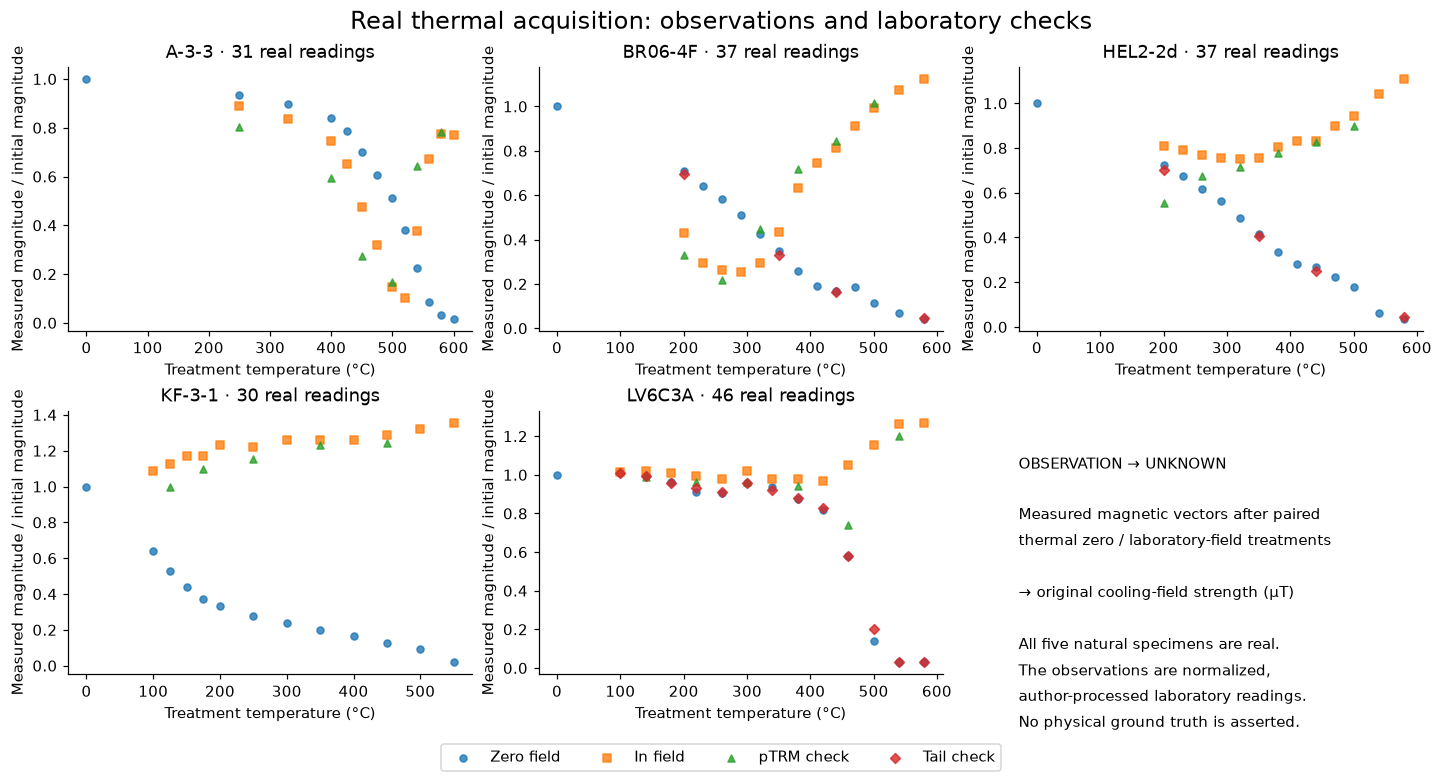

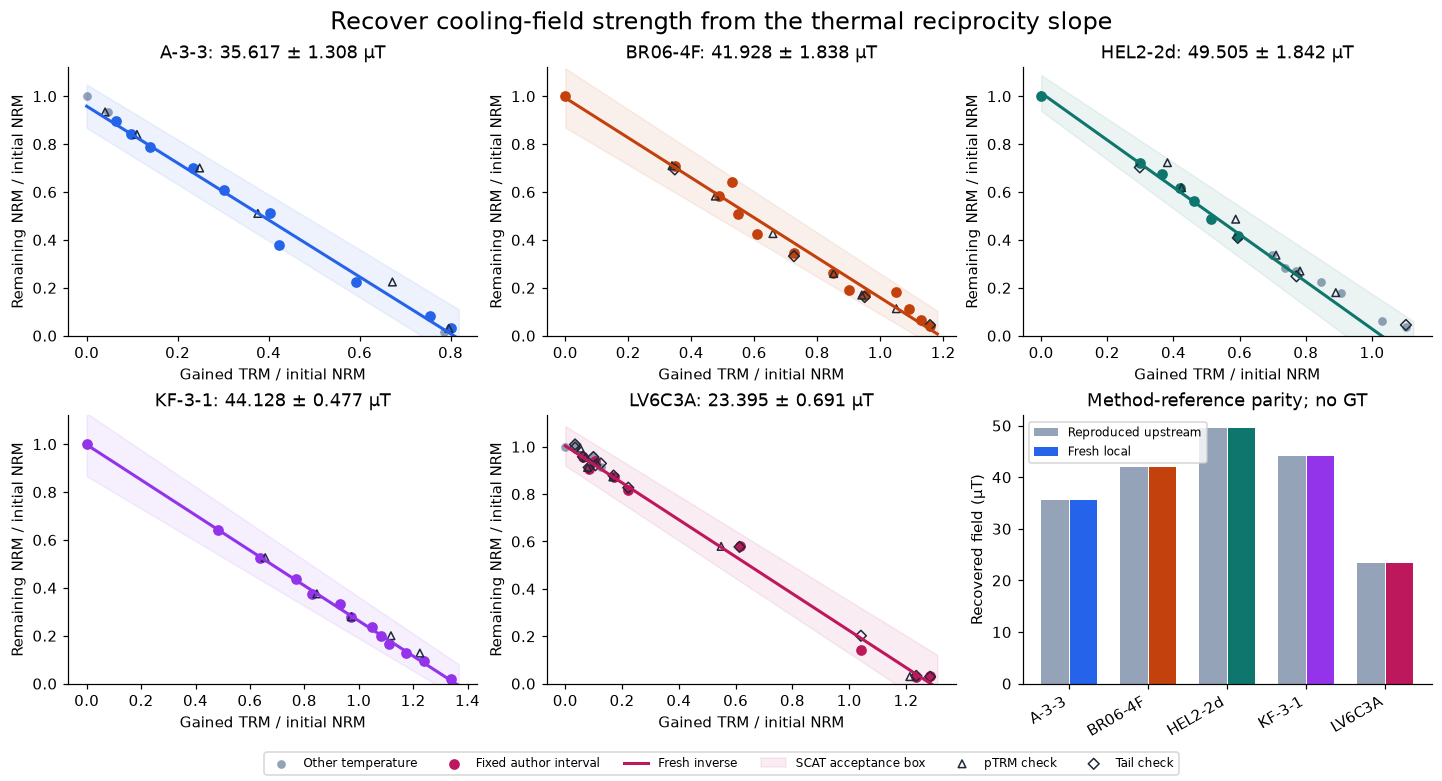

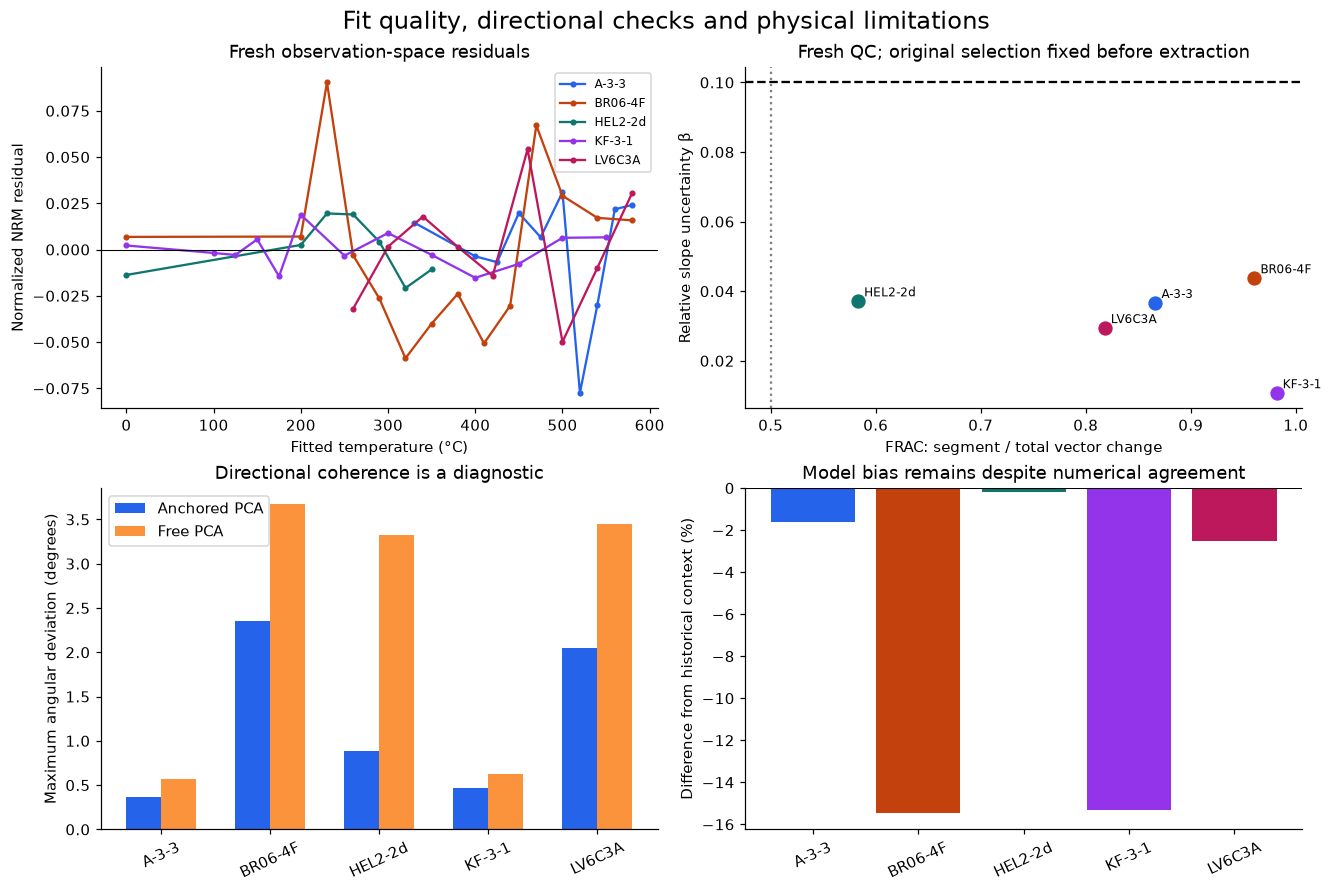

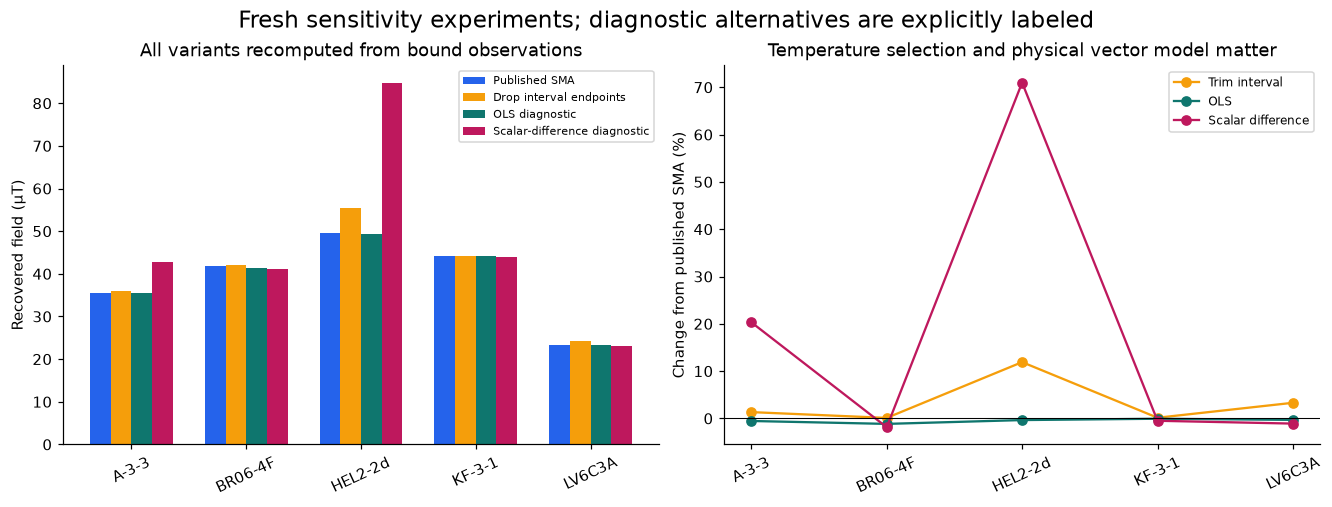

Fresh interval trimming: [[36.09222073 41.97418008 55.3964822  44.19289278 24.16901791]]
Fresh OLS diagnostic: [[35.42429967 41.44445159 49.33345146 44.09990262 23.3239349 ]]
Fresh scalar-difference diagnostic: [[42.85596858 41.15236673 84.64223475 43.9093861  23.14017711]]
Historical-context discrepancy (%), NOT an independent GT score: [[ -1.61184667 -15.46752831  -0.19196442 -15.30088956  -2.51962651]]


In [3]:
figures,experiments=comparison_figures(raw,reconstruction,diagnostics,upstream)
for figure in figures:
    display(figure)
    plt.close(figure)
print('Fresh interval trimming:',experiments['trimmed'])
print('Fresh OLS diagnostic:',experiments['ols'])
print('Fresh scalar-difference diagnostic:',experiments['scalar_difference'])
historical_percent=100*(reconstruction/upstream['expected_historical']-1)
print('Historical-context discrepancy (%), NOT an independent GT score:',historical_percent)
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_measurements.npz',reconstruction=reconstruction,runtime_seconds=np.array(runtime),beta=np.array([[d['beta'] for d in diagnostics]]),frac=np.array([[d['frac'] for d in diagnostics]]),mad=np.array([[d['mad'] for d in diagnostics]]),**experiments)

## Conclusion

The complete benchmark path reconstructs all five real specimens from measured magnetic vectors and known laboratory fields. Independent upstream parity verifies preprocessing, vector acquisition, signed regression, uncertainty, PCA, FRAC and SCAT. The figures expose residual model error and the effect of statistical/physical simplifications rather than hiding those differences behind a numerical pass.

Temperature selection changes the answer; historical expectations differ from the reconstructed field for some specimens even when the original method is exactly reproduced. Mineral alteration, nonideal grain behavior and unmeasured nuisance processes remain limitations. The benchmark therefore scores a validated standard-method inverse, with no invented physical GT. Corrected RS25b and the unselected poor calibration specimens are provenance diagnostics rather than extra successful reconstructions.